# NASA C-MAPSS RUL Prediction

## Model Training

This notebook trains the four cycle-level regression models planned in the data-preparation notebook:

- Linear Regression
- Support Vector Regression (SVR)
- Random Forest
- XGBoost

Each model is trained on FD001, FD002, FD003, and FD004. That gives 16 model-dataset results.

The official test set is not used to choose features or hyperparameters. It is scored once, after those choices are fixed.


## Experimental Setup

The prepared files in `processed_data` are used as they were saved.

- Each training row is one engine cycle. The inputs are the operating settings and sensor readings kept in `retained_features.json`. Constant features were already removed from the training split of each subset.
- Training and validation RUL are capped at 125 cycles. Values at or below 125 stay unchanged.
- Validation uses the saved 80/20 engine split (`random_state` 42). No engine appears in both partitions.
- The primary test target is the official RUL at the last observed cycle of each test engine. FD001 uses `X_test_FD001_full.csv` and `y_test_FD001_full.csv`, which contain the full feature set. The earlier 15-column FD001 test file is not used.
- A sensitivity score compares the same predictions with official RUL capped at 125, so the test target matches the training target.
- Linear Regression and SVR are standardized with `StandardScaler`, fit on the training partition only. Random Forest and XGBoost are not scaled.
- Hyperparameters are chosen separately for each dataset by validation RMSE. Ties go to the lower validation MAE, then the lower validation NASA score.
- SVR uses an RBF kernel. Its candidates are fit on a seeded sample of about 8,000 training cycles, using whole engines, and scored on the full validation partition. The winning settings are then refit on every training cycle. The other three models are tuned on the full training partition.
- RMSE and MAE average the error per cycle or per test engine. The NASA score is a sum, so subsets with more test engines accumulate a larger score even when the typical error is similar. RMSE and MAE are the fairer metrics for comparing FD001 with FD002 or FD004.

Predictions are not clipped. A model can predict below 0 or above 125.


In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass

cwd = Path.cwd()
if (cwd / "processed_data" / "retained_features.json").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "processed_data" / "retained_features.json").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Could not find processed_data/retained_features.json")

PROCESSED_PATH = PROJECT_ROOT / "processed_data"
RESULTS_PATH = PROJECT_ROOT / "results"
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
RUL_CAP = 125
SVR_SEARCH_ROWS = 8000
SUBSETS = ["FD001", "FD002", "FD003", "FD004"]
MODEL_NAMES = ["Linear Regression", "SVR", "Random Forest", "XGBoost"]

print("Project folder:", PROJECT_ROOT)
print("Results folder:", RESULTS_PATH)


Project folder: C:\Users\Eyasu\OneDrive - Minnesota State\Documents\GitHub\C_MAPSS_RUL_Project
Results folder: C:\Users\Eyasu\OneDrive - Minnesota State\Documents\GitHub\C_MAPSS_RUL_Project\results


In [2]:
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def nasa_score(y_true, y_pred):
    """Asymmetric NASA score. d = predicted RUL - true RUL.

    Early predictions (d < 0) use the divisor 13.
    Late predictions (d >= 0) use the divisor 10.
    Lower is better.
    """
    d = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
    with np.errstate(over="ignore"):
        terms = np.where(
            d < 0,
            np.exp(-d / 13.0) - 1.0,
            np.exp(d / 10.0) - 1.0,
        )
    return float(np.sum(terms))


def evaluate(y_true, y_pred):
    return {
        "RMSE": rmse(y_true, y_pred),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "NASA": nasa_score(y_true, y_pred),
    }


def is_better(candidate, incumbent):
    """Validation RMSE, then MAE, then NASA. Lower is better."""
    if incumbent is None:
        return True
    for key in ("RMSE", "MAE", "NASA"):
        if candidate[key] < incumbent[key] - 1e-9:
            return True
        if candidate[key] > incumbent[key] + 1e-9:
            return False
    return False


# Known-answer checks from the preparation notebook.
assert nasa_score([50], [50]) == 0.0
assert round(nasa_score([50], [40]), 4) == 1.1581
assert round(nasa_score([50], [60]), 4) == 1.7183
assert round(rmse([0, 0], [3, 4]), 4) == 3.5355
assert mean_absolute_error([10, 20], [12, 18]) == 2.0
print("Metric checks passed.")


Metric checks passed.


In [3]:
retained_features = json.loads((PROCESSED_PATH / "retained_features.json").read_text())


def load_subset(subset):
    """Load one subset the same way the preparation notebook does."""
    features = retained_features[subset]
    train_df = pd.read_csv(PROCESSED_PATH / f"train_{subset}_split.csv")
    val_df = pd.read_csv(PROCESSED_PATH / f"val_{subset}_split.csv")

    if subset == "FD001":
        test_features = pd.read_csv(PROCESSED_PATH / "X_test_FD001_full.csv")
        test_rul = pd.read_csv(PROCESSED_PATH / "y_test_FD001_full.csv")["RUL"]
    else:
        test_features = pd.read_csv(PROCESSED_PATH / f"X_test_{subset}.csv")
        test_rul = pd.read_csv(PROCESSED_PATH / f"y_test_{subset}.csv")["RUL"]

    missing = [
        column for column in features
        if column not in train_df.columns or column not in test_features.columns
    ]
    if missing:
        raise ValueError(f"{subset} is missing features: {missing}")

    overlap = set(train_df["unit"]).intersection(val_df["unit"])
    if overlap:
        raise ValueError(f"{subset} has engines in both train and validation: {sorted(overlap)[:5]}")

    return {
        "features": features,
        "train_df": train_df,
        "X_train": train_df[features],
        "y_train": np.minimum(train_df["RUL"].to_numpy(), RUL_CAP),
        "X_val": val_df[features],
        "y_val": np.minimum(val_df["RUL"].to_numpy(), RUL_CAP),
        "X_test": test_features[features],
        "y_test": test_rul.to_numpy(),
        "y_test_capped": np.minimum(test_rul.to_numpy(), RUL_CAP),
    }


def sample_training_engines(train_df, max_rows, seed):
    """Keep whole engines until the sample has about max_rows cycles."""
    engine_sizes = train_df.groupby("unit").size()
    engines = engine_sizes.index.to_numpy().copy()
    rng = np.random.default_rng(seed)
    rng.shuffle(engines)

    chosen = []
    rows = 0
    for engine in engines:
        chosen.append(int(engine))
        rows += int(engine_sizes.loc[engine])
        if rows >= max_rows:
            break
    return train_df[train_df["unit"].isin(chosen)].copy()


for subset in SUBSETS:
    data = load_subset(subset)
    print(
        f"{subset}: train {data['X_train'].shape}, "
        f"val {data['X_val'].shape}, test {data['X_test'].shape}, "
        f"features {len(data['features'])}, "
        f"y_train max {data['y_train'].max():.0f}, "
        f"official test max {data['y_test'].max():.0f}"
    )


FD001: train (16561, 17), val (4070, 17), test (100, 17), features 17, y_train max 125, official test max 145
FD002: train (43464, 24), val (10295, 24), test (259, 24), features 24, y_train max 125, official test max 194


FD003: train (20012, 18), val (4708, 18), test (100, 18), features 18, y_train max 125, official test max 145


FD004: train (49294, 24), val (11955, 24), test (248, 24), features 24, y_train max 125, official test max 195


## Hyperparameter Search

The grids below are the settings compared on the validation partition. The final tables use the winner for each model and dataset.

SVR's `epsilon` is the width of the no-penalty tube, in RUL cycles. The search uses 1 and 10 cycles rather than a fraction of a cycle.

Random Forest uses 200 trees during the search and keeps that fitted model when it wins. XGBoost uses 300 trees. Both are fit on the full training partition for every candidate.


In [4]:
RF_GRID = [
    {"n_estimators": 200, "max_depth": depth, "min_samples_leaf": leaf, "max_features": 1.0}
    for depth in (10, 20, None)
    for leaf in (1, 5)
]

XGB_GRID = [
    {
        "n_estimators": 300,
        "learning_rate": learning_rate,
        "max_depth": depth,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
    }
    for learning_rate in (0.05, 0.1)
    for depth in (3, 6)
]

SVR_GRID = [
    {"kernel": "rbf", "C": c_value, "epsilon": epsilon, "gamma": "scale"}
    for c_value in (1.0, 10.0, 100.0)
    for epsilon in (1.0, 10.0)
]

print("Random Forest candidates:", len(RF_GRID))
print("XGBoost candidates:", len(XGB_GRID))
print("SVR candidates:", len(SVR_GRID))
print("Linear Regression candidates: 1")


Random Forest candidates: 6
XGBoost candidates: 4
SVR candidates: 6
Linear Regression candidates: 1


In [5]:
def make_model(model_name, params):
    if model_name == "Linear Regression":
        return Pipeline([
            ("scale", StandardScaler()),
            ("model", LinearRegression()),
        ])
    if model_name == "SVR":
        return Pipeline([
            ("scale", StandardScaler()),
            ("model", SVR(cache_size=1000, **params)),
        ])
    if model_name == "Random Forest":
        return RandomForestRegressor(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params,
        )
    if model_name == "XGBoost":
        return XGBRegressor(
            objective="reg:squarederror",
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params,
        )
    raise ValueError(model_name)


def grid_for(model_name):
    if model_name == "Linear Regression":
        return [{}]
    if model_name == "SVR":
        return SVR_GRID
    if model_name == "Random Forest":
        return RF_GRID
    if model_name == "XGBoost":
        return XGB_GRID
    raise ValueError(model_name)


def params_label(params):
    if not params:
        return "defaults"
    return ", ".join(f"{key}={value}" for key, value in params.items())


def score_split(name, y_true, y_pred):
    scores = evaluate(y_true, y_pred)
    return {f"{name}_{key}": value for key, value in scores.items()}


## Train And Select

The next cell fits every candidate, chooses the validation winner, and scores that fitted model on the official test set. Partial results are written to `results/` after each dataset so a long run can be inspected while it is still going.


In [6]:
search_log = []
results = []
selected = {}
_log_path = RESULTS_PATH / "training_log.txt"
_log_path.write_text("", encoding="utf-8")

def log(message):
    print(message)
    with _log_path.open("a", encoding="utf-8") as log_file:
        log_file.write(message + "\n")

for subset in SUBSETS:
    data = load_subset(subset)
    log("\n" + "=" * 60)
    log(subset)
    log("=" * 60)
    selected[subset] = {}

    for model_name in MODEL_NAMES:
        log(f"\n{model_name}")
        best_scores = None
        best_params = None
        best_model = None

        if model_name == "SVR":
            search_frame = sample_training_engines(
                data["train_df"], SVR_SEARCH_ROWS, RANDOM_STATE
            )
            X_search = search_frame[data["features"]]
            y_search = np.minimum(search_frame["RUL"].to_numpy(), RUL_CAP)
            log(f"  SVR search rows: {len(search_frame)} from {search_frame['unit'].nunique()} engines")
        else:
            X_search = data["X_train"]
            y_search = data["y_train"]

        for params in grid_for(model_name):
            model = make_model(model_name, params)
            started = time.perf_counter()
            model.fit(X_search, y_search)
            fit_seconds = time.perf_counter() - started
            val_pred = model.predict(data["X_val"])
            val_scores = evaluate(data["y_val"], val_pred)
            log(
                f"  {params_label(params)} | "
                f"val RMSE {val_scores['RMSE']:.2f} | "
                f"{fit_seconds:.1f}s"
            )
            search_log.append({
                "dataset": subset,
                "model": model_name,
                "stage": "search",
                "fit_rows": int(len(X_search)),
                "params": params_label(params),
                "fit_seconds": fit_seconds,
                **val_scores,
            })
            if is_better(val_scores, best_scores):
                best_scores = val_scores
                best_params = params
                best_model = model

        if model_name == "SVR":
            best_model = make_model(model_name, best_params)
            final_started = time.perf_counter()
            best_model.fit(data["X_train"], data["y_train"])
            fit_seconds = time.perf_counter() - final_started
        else:
            winning_search = [
                entry for entry in search_log
                if entry["dataset"] == subset
                and entry["model"] == model_name
                and entry["params"] == params_label(best_params)
            ][-1]
            fit_seconds = winning_search["fit_seconds"]

        # Score the model that was actually selected. For SVR this is the
        # full-data refit. For the other models it is the winning candidate.
        val_pred = best_model.predict(data["X_val"])
        test_pred = best_model.predict(data["X_test"])
        row = {
            "dataset": subset,
            "model": model_name,
            "params": params_label(best_params),
            "fit_seconds": fit_seconds,
            "test_pred_min": float(np.min(test_pred)),
            "test_pred_max": float(np.max(test_pred)),
        }
        row.update(score_split("val", data["y_val"], val_pred))
        row.update(score_split("test", data["y_test"], test_pred))
        row.update(score_split("test_capped", data["y_test_capped"], test_pred))
        results.append(row)
        selected[subset][model_name] = best_params
        log(
            f"  selected: {params_label(best_params)} | "
            f"val RMSE {row['val_RMSE']:.2f} | "
            f"test RMSE {row['test_RMSE']:.2f}"
        )
        del best_model

    pd.DataFrame(results).to_csv(RESULTS_PATH / "model_comparison.csv", index=False)
    pd.DataFrame(search_log).to_csv(RESULTS_PATH / "hyperparameter_search.csv", index=False)

with (RESULTS_PATH / "selected_hyperparameters.json").open("w") as file:
    json.dump(selected, file, indent=2)

results_df = pd.DataFrame(results)
log("\nTraining finished.")



FD001

Linear Regression
  defaults | val RMSE 20.41 | 0.0s
  selected: defaults | val RMSE 20.41 | test RMSE 21.88

SVR
  SVR search rows: 8195 from 39 engines
  kernel=rbf, C=1.0, epsilon=1.0, gamma=scale | val RMSE 17.53 | 1.3s
  kernel=rbf, C=1.0, epsilon=10.0, gamma=scale | val RMSE 17.78 | 0.7s
  kernel=rbf, C=10.0, epsilon=1.0, gamma=scale | val RMSE 17.32 | 1.3s
  kernel=rbf, C=10.0, epsilon=10.0, gamma=scale | val RMSE 17.25 | 0.7s
  kernel=rbf, C=100.0, epsilon=1.0, gamma=scale | val RMSE 17.61 | 3.4s
  kernel=rbf, C=100.0, epsilon=10.0, gamma=scale | val RMSE 17.55 | 1.3s
  selected: kernel=rbf, C=10.0, epsilon=10.0, gamma=scale | val RMSE 17.19 | test RMSE 18.47

Random Forest
  n_estimators=200, max_depth=10, min_samples_leaf=1, max_features=1.0 | val RMSE 17.03 | 1.6s
  n_estimators=200, max_depth=10, min_samples_leaf=5, max_features=1.0 | val RMSE 17.01 | 1.5s
  n_estimators=200, max_depth=20, min_samples_leaf=1, max_features=1.0 | val RMSE 17.14 | 2.7s
  n_estimators=2

## Validation Results

These scores use the capped validation target. They are the scores of the selected models, so they guided the hyperparameter choice. They are not a second held-out test.

Validation NASA sums the penalty over every validation cycle. Test NASA sums it over one row per test engine. The validation NASA numbers are therefore much larger, and they should not be compared with the test NASA numbers.


In [7]:
val_table = results_df[
    ["dataset", "model", "params", "val_RMSE", "val_MAE", "val_NASA", "fit_seconds"]
].copy()
display(val_table.round(2))


,dataset,model,params,val_RMSE,val_MAE,val_NASA,fit_seconds
0,FD001,Linear Regression,defaults,20.41,16.48,28907.44,0.02
1,FD001,SVR,"kernel=rbf, C=10.0, epsilon=10.0, gamma=scale",17.19,12.75,39078.26,2.87
2,FD001,Random Forest,"n_estimators=200, max_depth=10, min_samples_le...",17.01,12.41,32317.30,1.54
3,FD001,XGBoost,"n_estimators=300, learning_rate=0.05, max_dept...",16.92,12.37,29547.04,0.21
4,FD002,Linear Regression,defaults,21.66,17.66,117674.19,0.03
5,FD002,SVR,"kernel=rbf, C=100.0, epsilon=10.0, gamma=scale",21.29,17.07,132507.02,31.30
6,FD002,Random Forest,"n_estimators=200, max_depth=None, min_samples_...",19.80,14.50,171309.19,14.57
7,FD002,XGBoost,"n_estimators=300, learning_rate=0.05, max_dept...",19.75,14.38,167241.79,0.99
8,FD003,Linear Regression,defaults,19.34,15.05,46729.64,0.04
9,FD003,SVR,"kernel=rbf, C=10.0, epsilon=10.0, gamma=scale",15.56,11.27,39086.48,3.55


## Official Test Results

This is the primary comparison. The target is the official, uncapped test RUL. Lower is better for every metric.

The NASA score sums penalties across test engines. FD002 and FD004 have more than twice as many test engines as FD001 and FD003, so their NASA scores are not on the same scale.


In [8]:
test_table = results_df[
    [
        "dataset", "model", "test_RMSE", "test_MAE", "test_NASA",
        "test_pred_min", "test_pred_max",
    ]
].copy()
engine_counts = {"FD001": 100, "FD002": 259, "FD003": 100, "FD004": 248}
test_table["NASA_per_engine"] = test_table["test_NASA"] / test_table["dataset"].map(engine_counts)
display(test_table.round(2))


,dataset,model,test_RMSE,test_MAE,test_NASA,test_pred_min,test_pred_max,NASA_per_engine
0,FD001,Linear Regression,21.88,17.62,1307.55,6.34,140.32,13.08
1,FD001,SVR,18.47,13.38,1018.41,6.93,124.91,10.18
2,FD001,Random Forest,18.03,12.96,894.79,5.86,122.96,8.95
3,FD001,XGBoost,18.15,12.71,1024.02,6.89,122.70,10.24
4,FD002,Linear Regression,32.55,24.36,18581.85,-20.68,153.59,71.74
5,FD002,SVR,31.80,23.25,22150.26,-18.62,165.26,85.52
6,FD002,Random Forest,29.28,20.81,12227.72,2.60,123.65,47.21
7,FD002,XGBoost,28.87,20.43,10796.91,1.99,123.50,41.69
8,FD003,Linear Regression,22.36,18.03,1656.24,1.06,139.43,16.56
9,FD003,SVR,21.00,16.08,1777.60,9.67,128.35,17.78


## Sensitivity Check: Capped Test RUL

Training asked the models to predict RUL only up to 125. Some official test values are higher than 125, so part of the official-test error is built into that target mismatch. This table scores the same predictions against official RUL capped at 125.


In [9]:
capped_table = results_df[
    ["dataset", "model", "test_capped_RMSE", "test_capped_MAE", "test_capped_NASA"]
].copy()
display(capped_table.round(2))


,dataset,model,test_capped_RMSE,test_capped_MAE,test_capped_NASA
0,FD001,Linear Regression,20.79,16.57,1244.16
1,FD001,SVR,17.65,12.31,992.50
2,FD001,Random Forest,17.05,11.89,862.85
3,FD001,XGBoost,17.15,11.64,991.23
4,FD002,Linear Regression,21.47,17.61,2983.52
5,FD002,SVR,20.74,16.53,2964.62
6,FD002,Random Forest,17.50,13.32,2949.17
7,FD002,XGBoost,17.12,12.94,2938.94
8,FD003,Linear Regression,21.23,16.95,1586.61
9,FD003,SVR,19.93,14.59,1737.09


## Which Model Ranks First

Within each dataset, models are ranked by official test RMSE, MAE, and NASA score. A change in the winning model across metrics means the conclusion depends on which error the study emphasizes.


In [10]:
rank_rows = []
for subset, group in results_df.groupby("dataset", sort=False):
    print(f"\n{subset}")
    for metric, label in (
        ("test_RMSE", "RMSE"),
        ("test_MAE", "MAE"),
        ("test_NASA", "NASA"),
    ):
        ordered = group.sort_values(metric, ascending=True)
        winner = ordered.iloc[0]
        ranking = " > ".join(
            f"{row.model} ({getattr(row, metric):.2f})" for row in ordered.itertuples()
        )
        print(f"  {label}: {ranking}")
        rank_rows.append({
            "dataset": subset,
            "metric": label,
            "best_model": winner["model"],
            "best_value": winner[metric],
        })

rank_df = pd.DataFrame(rank_rows)
print("\nBest model by metric:")
display(rank_df.pivot(index="dataset", columns="metric", values="best_model").loc[SUBSETS])



FD001
  RMSE: Random Forest (18.03) > XGBoost (18.15) > SVR (18.47) > Linear Regression (21.88)
  MAE: XGBoost (12.71) > Random Forest (12.96) > SVR (13.38) > Linear Regression (17.62)
  NASA: Random Forest (894.79) > SVR (1018.41) > XGBoost (1024.02) > Linear Regression (1307.55)

FD002
  RMSE: XGBoost (28.87) > Random Forest (29.28) > SVR (31.80) > Linear Regression (32.55)
  MAE: XGBoost (20.43) > Random Forest (20.81) > SVR (23.25) > Linear Regression (24.36)
  NASA: XGBoost (10796.91) > Random Forest (12227.72) > Linear Regression (18581.85) > SVR (22150.26)

FD003
  RMSE: Random Forest (20.99) > SVR (21.00) > XGBoost (21.95) > Linear Regression (22.36)
  MAE: SVR (16.08) > Random Forest (16.42) > XGBoost (16.69) > Linear Regression (18.03)
  NASA: Linear Regression (1656.24) > SVR (1777.60) > Random Forest (1789.09) > XGBoost (2243.54)

FD004
  RMSE: Random Forest (30.18) > XGBoost (30.21) > Linear Regression (34.67) > SVR (35.12)
  MAE: XGBoost (22.47) > Random Forest (22.55) >

metric,MAE,NASA,RMSE
dataset,,,
FD001,XGBoost,Random Forest,Random Forest
FD002,XGBoost,XGBoost,XGBoost
FD003,SVR,Linear Regression,Random Forest
FD004,XGBoost,Random Forest,Random Forest


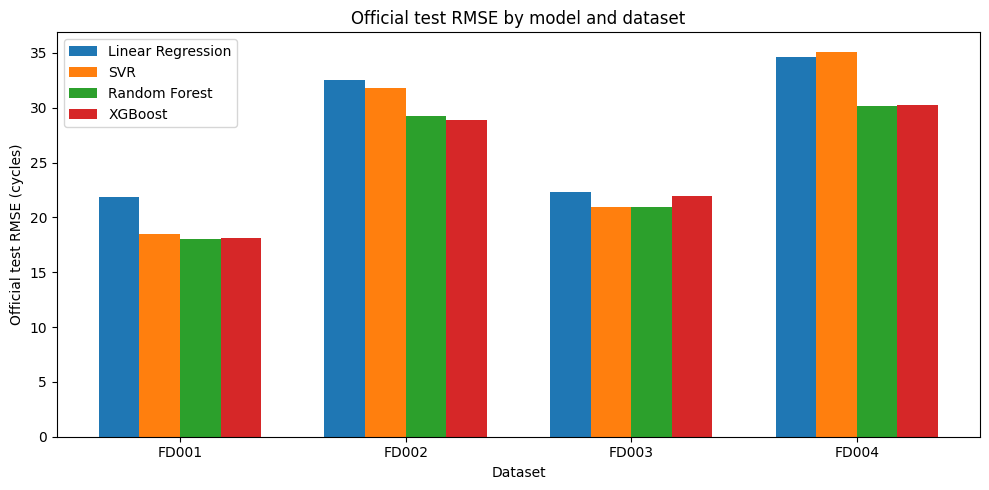

In [11]:
fig, axis = plt.subplots(figsize=(10, 5))
x = np.arange(len(SUBSETS))
width = 0.18

for index, model_name in enumerate(MODEL_NAMES):
    values = [
        results_df.loc[
            (results_df["dataset"] == subset) & (results_df["model"] == model_name),
            "test_RMSE",
        ].iloc[0]
        for subset in SUBSETS
    ]
    axis.bar(x + (index - 1.5) * width, values, width, label=model_name)

axis.set_xticks(x)
axis.set_xticklabels(SUBSETS)
axis.set_ylabel("Official test RMSE (cycles)")
axis.set_xlabel("Dataset")
axis.set_title("Official test RMSE by model and dataset")
axis.legend()
fig.tight_layout()
fig.savefig(RESULTS_PATH / "test_rmse_by_model.png", dpi=150)
plt.show()


## Saved Files

- `results/model_comparison.csv` stores the selected model for every dataset, with validation, official-test, and capped-test scores.
- `results/hyperparameter_search.csv` stores every candidate that was scored on validation.
- `results/selected_hyperparameters.json` stores the winning settings.
- `results/test_rmse_by_model.png` stores the official-test RMSE chart.

The search file records the SVR candidates before they were refit on the full training partition. The comparison file records the refit SVR model.
